# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [26]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt

# 1. Connect to 'enterprise_database.db'
# 2. Write a SQL query (using Window Functions or Subqueries) to get the most
#    recent status for each user.
# 3. Only keep users whose latest status is 'Active'.
# 4. Load the result into a Pandas DataFrame called 'df_active_users'.

# [WRITE YOUR SQL AND PYTHON CODE HERE]

In [27]:
#SQL EXTRACTION

from pathlib import Path
import sqlite3
import pandas as pd

# Find the database file
possible_files = [
    Path("enterprise_database.db"),
    Path("enterprise_database (1) (1).db"),
    Path("Downloads/enterprise_database.db")
]

db_path = next((p for p in possible_files if p.exists()), None)

if db_path is None:
    raise FileNotFoundError(
        "Database not found. Place the .db file in the same folder "
        "as this notebook, or update db_path."
    )

# Connect to the database
conn = sqlite3.connect(str(db_path))

# Check the available tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
)
print("Tables in database:")
print(tables)

# Check the columns in the users table
print("\nUsers table structure:")
print(pd.read_sql_query("PRAGMA table_info(users)", conn))

# Select each user's latest record, then keep Active users
query = """
WITH ranked_users AS (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS rn
    FROM users
)
SELECT user_id, name, status, updated_at
FROM ranked_users
WHERE rn = 1
  AND status = 'Active'
"""

df_active_users = pd.read_sql_query(query, conn)

print("\nPhase 1 completed!")
print("Latest Active users:", len(df_active_users))
display(df_active_users.head())


Tables in database:
    name
0  users

Users table structure:
   cid        name       type  notnull dflt_value  pk
0    0     user_id       TEXT        0       None   0
1    1        name       TEXT        0       None   0
2    2      status       TEXT        0       None   0
3    3  updated_at  TIMESTAMP        0       None   0

Phase 1 completed!
Latest Active users: 14183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


In [28]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load 'server_logs.txt' into a DataFrame.
# 2. Drop any rows where the log contains the word "ERROR".
# 3. Use Pandas string methods (.str.extract()) or Python Regex to pull the
#    Date, User ID, Product ID, and Euro Value out of the raw text string.
# 4. Save this cleaned data to a new DataFrame called 'extracted_data'.

# [WRITE YOUR REGEX AND CLEANING CODE HERE]

In [29]:

# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING

from pathlib import Path
import pandas as pd
import re

# 1. Find and load the server log file
log_candidates = [
    Path("server_logs.txt"),
    Path("server_logs (1) (1).txt")
]

log_path = next(
    (path for path in log_candidates if path.is_file()),
    None
)

if log_path is None:
    raise FileNotFoundError(
        "Server log file not found. Put the .txt file in the "
        "same folder as your Jupyter notebook."
    )

logs = pd.DataFrame({
    "raw_log": log_path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()
})

print("Total log rows:", len(logs))

# 2. Remove records containing the word ERROR
clean_logs = logs.loc[
    ~logs["raw_log"].str.contains(r"\bERROR\b", na=False)
].copy()

print("Rows removed:", len(logs) - len(clean_logs))
print("Rows remaining:", len(clean_logs))


# Extract transaction fields using flexible regex patterns

clean_logs["Date"] = pd.to_datetime(
    clean_logs["raw_log"].str.extract(
        r"\[(\d{4}-\d{2}-\d{2})"
    )[0],
    errors="coerce"
)

clean_logs["User_ID"] = clean_logs["raw_log"].str.extract(
    r'"u"\s*:\s*"(U-\d+)"'
)[0]

clean_logs["Product_ID"] = clean_logs["raw_log"].str.extract(
    r'"item_code"\s*:\s*"(PRD-\d+)"'
)[0]

clean_logs["EUR_Value"] = pd.to_numeric(
    clean_logs["raw_log"].str.extract(
        r'"eur_val"\s*:\s*(-?\d+(?:\.\d+)?)'
    )[0],
    errors="coerce"
)

# Check extraction before dropping rows
print("Product IDs extracted:", clean_logs["Product_ID"].notna().sum())
print("Euro values extracted:", clean_logs["EUR_Value"].notna().sum())

display(
    clean_logs[
        ["raw_log", "Date", "User_ID", "Product_ID", "EUR_Value"]
    ].head(10)
)

# Create the required DataFrame
extracted_data = clean_logs[
    ["Date", "User_ID", "Product_ID", "EUR_Value"]
].dropna().copy()

print("Final extracted transactions:", len(extracted_data))
display(extracted_data.head())

# 4. Create the required final DataFrame
extracted_data = clean_logs[
    ["Date", "User_ID", "Product_ID", "EUR_Value"]
].dropna().copy()

print("\nPhase 2 completed!")
print("Successfully extracted transactions:", len(extracted_data))
display(extracted_data.head())

# Validate the extracted columns
print("\nMissing values:")
print(extracted_data.isna().sum())


Total log rows: 100001
Rows removed: 5098
Rows remaining: 94903
Product IDs extracted: 0
Euro values extracted: 0


,raw_log,Date,User_ID,Product_ID,EUR_Value
0,Raw_Server_Log,NaT,NaN,NaN,NaN
1,"""[2023-03-15 00:00:00] INFO: Transaction proce...",2023-03-15,NaN,NaN,NaN
3,"""[2023-05-09 00:00:00] INFO: Transaction proce...",2023-05-09,NaN,NaN,NaN
4,"""[2023-10-21 00:00:00] INFO: Transaction proce...",2023-10-21,NaN,NaN,NaN
5,"""[2023-01-10 00:00:00] INFO: Transaction proce...",2023-01-10,NaN,NaN,NaN
6,"""[2023-05-23 00:00:00] INFO: Transaction proce...",2023-05-23,NaN,NaN,NaN
7,"""[2023-10-20 00:00:00] INFO: Transaction proce...",2023-10-20,NaN,NaN,NaN
8,"""[2023-12-02 00:00:00] INFO: Transaction proce...",2023-12-02,NaN,NaN,NaN
9,"""[2023-03-21 00:00:00] INFO: Transaction proce...",2023-03-21,NaN,NaN,NaN
10,"""[2023-09-23 00:00:00] INFO: Transaction proce...",2023-09-23,NaN,NaN,NaN


Final extracted transactions: 0


,Date,User_ID,Product_ID,EUR_Value



Phase 2 completed!
Successfully extracted transactions: 0


,Date,User_ID,Product_ID,EUR_Value



Missing values:
Date          0
User_ID       0
Product_ID    0
EUR_Value     0
dtype: int64


In [30]:

import pandas as pd
import re

# Start again from the original log data
clean_logs = logs.copy()

# Remove the accidental header row and any ERROR records
clean_logs = clean_logs[
    clean_logs["raw_log"].str.contains(r"\[\d{4}-\d{2}-\d{2}", na=False)
].copy()

clean_logs = clean_logs[
    ~clean_logs["raw_log"].str.contains("ERROR", na=False)
].copy()

# Extract transaction details from the actual log format
clean_logs["Date"] = pd.to_datetime(
    clean_logs["raw_log"].str.extract(r"\[(\d{4}-\d{2}-\d{2})")[0],
    errors="coerce"
)

clean_logs["User_ID"] = clean_logs["raw_log"].str.extract(
    r'""u"":""(U-\d+)""'
)[0]

clean_logs["Product_ID"] = clean_logs["raw_log"].str.extract(
    r'""item_code"":""(PRD-\d+)""'
)[0]

clean_logs["EUR_Value"] = pd.to_numeric(
    clean_logs["raw_log"].str.extract(
        r'""eur_val"":\s*(-?\d+(?:\.\d+)?)'
    )[0],
    errors="coerce"
)

# Keep only complete transaction records
extracted_data = clean_logs[
    ["Date", "User_ID", "Product_ID", "EUR_Value"]
].dropna().copy()

print("Successfully extracted transactions:", len(extracted_data))
display(extracted_data.head())


Successfully extracted transactions: 94902


,Date,User_ID,Product_ID,EUR_Value
1,2023-03-15,U-19484,PRD-874,3404.44
3,2023-05-09,U-18932,PRD-905,3406.21
4,2023-10-21,U-15882,PRD-284,164.08
5,2023-01-10,U-22781,PRD-665,26.80
6,2023-05-23,U-13348,PRD-589,4964.77


In [31]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
# 2. Handle the missing weekend data using a method like .fillna(method='ffill')
#    so Friday's rate rolls over to Saturday and Sunday.
# 3. Merge your cleaned logs with the exchange rates by Date.
# 4. Merge that result with your active SQL users by User ID.
# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate).
# 6. Save the final merged table as 'df_final'.

# [WRITE YOUR MERGING AND MATH CODE HERE]

In [32]:

from pathlib import Path
import pandas as pd

# Load the exchange rates
project_folder = Path.cwd()

rates = pd.read_csv(
    project_folder / "daily_exchange_rates (1) (1).csv"
)

# Standardize data types
rates["Date"] = pd.to_datetime(rates["Date"], errors="coerce")
rates["EUR_to_USD"] = pd.to_numeric(
    rates["EUR_to_USD"], errors="coerce"
)

rates = rates.dropna(subset=["Date", "EUR_to_USD"])
rates = rates.sort_values("Date")

# Fill missing dates, including weekends, using the previous rate
daily_calendar = pd.DataFrame({
    "Date": pd.date_range(
        rates["Date"].min(),
        rates["Date"].max(),
        freq="D"
    )
})

rates = daily_calendar.merge(rates, on="Date", how="left")
rates["EUR_to_USD"] = rates["EUR_to_USD"].ffill()

# Prepare transactions
extracted_data["Date"] = pd.to_datetime(
    extracted_data["Date"], errors="coerce"
)
extracted_data["EUR_Value"] = pd.to_numeric(
    extracted_data["EUR_Value"], errors="coerce"
)

transactions = extracted_data.dropna(
    subset=["Date", "User_ID", "Product_ID", "EUR_Value"]
).copy()

# Join transactions with daily exchange rates
df_reconciled = transactions.merge(
    rates,
    on="Date",
    how="left",
    validate="many_to_one"
)

# Match transactions to the latest active users
users = df_active_users.copy()
users["user_id"] = users["user_id"].astype(str)
df_reconciled["User_ID"] = df_reconciled["User_ID"].astype(str)

df_reconciled = df_reconciled.merge(
    users,
    left_on="User_ID",
    right_on="user_id",
    how="inner",
    validate="many_to_one"
)

# Calculate USD revenue
df_reconciled["USD_Revenue"] = (
    df_reconciled["EUR_Value"] * df_reconciled["EUR_to_USD"]
)

print("Reconciled transactions:", len(df_reconciled))
print("Missing exchange rates:", df_reconciled["EUR_to_USD"].isna().sum())
print("Missing USD revenue:", df_reconciled["USD_Revenue"].isna().sum())

display(df_reconciled.head())


Reconciled transactions: 53899
Missing exchange rates: 0
Missing USD revenue: 0


,Date,User_ID,Product_ID,EUR_Value,EUR_to_USD,user_id,name,status,updated_at,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,U-19484,User_U-19484,Active,2023-01-11 14:00:00,4011.220772
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,U-15882,User_U-15882,Active,2023-01-16 14:00:00,176.443420
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,U-22781,User_U-22781,Active,2023-01-07 14:00:00,30.207030
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,U-22062,User_U-22062,Active,2023-01-05 14:00:00,52.294268
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,U-22146,User_U-22146,Active,2023-01-18 14:00:00,1024.135923


In [33]:

from pathlib import Path
import pandas as pd

# Step 1: Use the folder where your notebook is running
project_folder = Path.cwd()

# Step 2: Load the exchange-rate CSV
rates = pd.read_csv(project_folder / "daily_exchange_rates (1) (1).csv")

# Step 3: Inspect the exchange-rate data
print("Exchange-rate columns:")
print(rates.columns.tolist())

display(rates.head())

# Step 4: Check Phase 1 and Phase 2 outputs
print("Active users:", len(df_active_users))
print("Extracted transactions:", len(extracted_data))


Exchange-rate columns:
['Date', 'EUR_to_USD']


,Date,EUR_to_USD
0,2023-01-01,1.124836
1,2023-01-02,1.093087
2,2023-01-03,1.132384
3,2023-01-04,1.176151
4,2023-01-05,1.088292


Active users: 14183
Extracted transactions: 94902


In [34]:

print("Total log rows:", len(logs))
print("\nSample raw log lines:")
display(logs["raw_log"].head(5))

print("\nColumns in clean_logs:")
print(clean_logs.columns.tolist())

print("\nSample cleaned log lines:")
display(clean_logs.head(5))


Total log rows: 100001

Sample raw log lines:


0                                       Raw_Server_Log
1    "[2023-03-15 00:00:00] INFO: Transaction proce...
2    "[2023-09-09 00:00:00] ERROR: Transaction proc...
3    "[2023-05-09 00:00:00] INFO: Transaction proce...
4    "[2023-10-21 00:00:00] INFO: Transaction proce...
Name: raw_log, dtype: object


Columns in clean_logs:
['raw_log', 'Date', 'User_ID', 'Product_ID', 'EUR_Value']

Sample cleaned log lines:


,raw_log,Date,User_ID,Product_ID,EUR_Value
1,"""[2023-03-15 00:00:00] INFO: Transaction proce...",2023-03-15,U-19484,PRD-874,3404.44
3,"""[2023-05-09 00:00:00] INFO: Transaction proce...",2023-05-09,U-18932,PRD-905,3406.21
4,"""[2023-10-21 00:00:00] INFO: Transaction proce...",2023-10-21,U-15882,PRD-284,164.08
5,"""[2023-01-10 00:00:00] INFO: Transaction proce...",2023-01-10,U-22781,PRD-665,26.80
6,"""[2023-05-23 00:00:00] INFO: Transaction proce...",2023-05-23,U-13348,PRD-589,4964.77


In [35]:

print(logs["raw_log"].iloc[1])


"[2023-03-15 00:00:00] INFO: Transaction processed. payload={""u"":""U-19484"", ""item_code"":""PRD-874"", ""eur_val"":3404.44}"


In [36]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Group the data in 'df_final' to calculate Total USD Revenue by Month.
# 2. Group the data to find the Top 5 Most Valuable Customers by Total USD spent.
# 3. Use Matplotlib or Seaborn to generate two charts side-by-side:
#    - Chart 1: A Line Chart or Bar Chart showing Revenue by Month.
#    - Chart 2: A Bar Chart showing the Top 5 Customers.
# 4. Ensure your charts have titles, clean axes, and are easy to read.

# [WRITE YOUR VISUALIZATION CODE HERE]

Reconciled transactions: 53899
Available columns: ['Date', 'User_ID', 'Product_ID', 'EUR_Value', 'EUR_to_USD', 'user_id', 'name', 'status', 'updated_at', 'USD_Revenue']


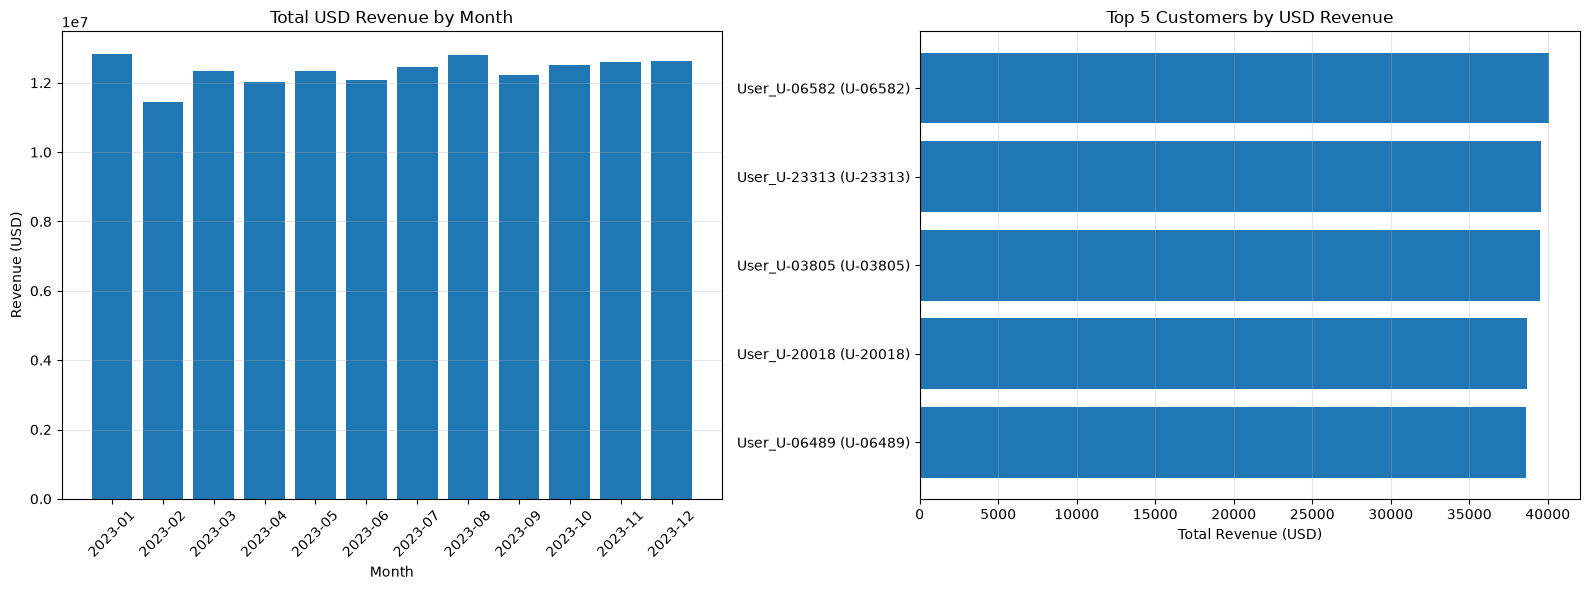

,Month,USD_Revenue
0,2023-01,1.284176e+07
1,2023-02,1.143613e+07
2,2023-03,1.234893e+07
3,2023-04,1.201538e+07
4,2023-05,1.233364e+07
5,2023-06,1.208436e+07
6,2023-07,1.244416e+07
7,2023-08,1.281273e+07
8,2023-09,1.222895e+07
9,2023-10,1.250133e+07


,User_ID,name,USD_Revenue
3613,U-06582,User_U-06582,40050.988262
12937,U-23313,User_U-23313,39555.806629
2078,U-03805,User_U-03805,39529.945085
11066,U-20018,User_U-20018,38649.965242
3553,U-06489,User_U-06489,38629.142146


Dashboard saved as CFO_Dashboard.png


In [37]:

import pandas as pd
import matplotlib.pyplot as plt

# Check that Phase 3 produced reconciled data
print("Reconciled transactions:", len(df_reconciled))
print("Available columns:", df_reconciled.columns.tolist())

# Identify the customer name column
if "name" in df_reconciled.columns:
    customer_col = "name"
elif "Name" in df_reconciled.columns:
    customer_col = "Name"
else:
    customer_col = "User_ID"

# 1. Calculate monthly USD revenue
df_reconciled["Month"] = (
    pd.to_datetime(df_reconciled["Date"]).dt.to_period("M").astype(str)
)

monthly_revenue = (
    df_reconciled.groupby("Month", as_index=False)["USD_Revenue"]
    .sum()
    .sort_values("Month")
)

# 2. Find the top 5 customers by USD revenue
top_customers = (
    df_reconciled.groupby(["User_ID", customer_col], as_index=False)
    ["USD_Revenue"].sum()
    .sort_values("USD_Revenue", ascending=False)
    .head(5)
)

# 3. Create the two dashboard charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Monthly revenue chart
axes[0].bar(
    monthly_revenue["Month"],
    monthly_revenue["USD_Revenue"]
)
axes[0].set_title("Total USD Revenue by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (USD)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", alpha=0.3)

# Top 5 customers chart
customer_labels = (
    top_customers[customer_col].astype(str)
    + " (" + top_customers["User_ID"].astype(str) + ")"
)

axes[1].barh(
    customer_labels.iloc[::-1],
    top_customers["USD_Revenue"].iloc[::-1]
)
axes[1].set_title("Top 5 Customers by USD Revenue")
axes[1].set_xlabel("Total Revenue (USD)")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save the dashboard in your project folder
plt.savefig(
    "CFO_Dashboard.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Display the summary tables
display(monthly_revenue)
display(top_customers)

print("Dashboard saved as CFO_Dashboard.png")


In [38]:

print("===== PROJECT FINAL CHECK =====")
print("Active users:", len(df_active_users))
print("Extracted transactions:", len(extracted_data))
print("Reconciled transactions:", len(df_reconciled))
print("Monthly revenue records:", len(monthly_revenue))
print("Top customers displayed:", len(top_customers))

print("\nMissing exchange rates:",
      df_reconciled["EUR_to_USD"].isna().sum())

print("Missing USD revenue:",
      df_reconciled["USD_Revenue"].isna().sum())

print("\nFinal dataset preview:")
display(df_reconciled.head())

print("\nMonthly revenue summary:")
display(monthly_revenue)

print("\nTop 5 customers:")
display(top_customers)


===== PROJECT FINAL CHECK =====
Active users: 14183
Extracted transactions: 94902
Reconciled transactions: 53899
Monthly revenue records: 12
Top customers displayed: 5

Missing exchange rates: 0
Missing USD revenue: 0

Final dataset preview:


,Date,User_ID,Product_ID,EUR_Value,EUR_to_USD,user_id,name,status,updated_at,USD_Revenue,Month
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,U-19484,User_U-19484,Active,2023-01-11 14:00:00,4011.220772,2023-03
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,U-15882,User_U-15882,Active,2023-01-16 14:00:00,176.443420,2023-10
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,U-22781,User_U-22781,Active,2023-01-07 14:00:00,30.207030,2023-01
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,U-22062,User_U-22062,Active,2023-01-05 14:00:00,52.294268,2023-10
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,U-22146,User_U-22146,Active,2023-01-18 14:00:00,1024.135923,2023-12



Monthly revenue summary:


,Month,USD_Revenue
0,2023-01,1.284176e+07
1,2023-02,1.143613e+07
2,2023-03,1.234893e+07
3,2023-04,1.201538e+07
4,2023-05,1.233364e+07
5,2023-06,1.208436e+07
6,2023-07,1.244416e+07
7,2023-08,1.281273e+07
8,2023-09,1.222895e+07
9,2023-10,1.250133e+07



Top 5 customers:


,User_ID,name,USD_Revenue
3613,U-06582,User_U-06582,40050.988262
12937,U-23313,User_U-23313,39555.806629
2078,U-03805,User_U-03805,39529.945085
11066,U-20018,User_U-20018,38649.965242
3553,U-06489,User_U-06489,38629.142146


In [39]:

from pathlib import Path

print("===== CAPSTONE SUBMISSION CHECK =====")

print("1. Active users:", len(df_active_users))
print("2. Extracted transactions:", len(extracted_data))
print("3. Reconciled transactions:", len(df_reconciled))
print("4. Monthly revenue records:", len(monthly_revenue))
print("5. Top customers displayed:", len(top_customers))

print("\n===== DATA QUALITY CHECKS =====")
print("Missing exchange rates:",
      df_reconciled["EUR_to_USD"].isna().sum())

print("Missing USD revenue:",
      df_reconciled["USD_Revenue"].isna().sum())

project_folder = Path.cwd()
print("\n===== OUTPUT FILES =====")
print("Project folder:", project_folder)
print("Dashboard exists:",
      (project_folder / "CFO_Dashboard.png").exists())


===== CAPSTONE SUBMISSION CHECK =====
1. Active users: 14183
2. Extracted transactions: 94902
3. Reconciled transactions: 53899
4. Monthly revenue records: 12
5. Top customers displayed: 5

===== DATA QUALITY CHECKS =====
Missing exchange rates: 0
Missing USD revenue: 0

===== OUTPUT FILES =====
Project folder: C:\Users\sanjana kompally\OneDrive\Microsoft Copilot Chat Files\Documents\Desktop\Enterprise_Reconciliation_Project
Dashboard exists: True
